# EWELD C24 — Modelli baseline di previsione (breve termine, orario)

Primo notebook di **modellazione** sul sotto-insieme siderurgico C24 di EWELD.
Obiettivo: prevedere il consumo elettrico **orario** sul breve termine (prossime ~24–48 ore)
partendo da modelli semplici e confrontabili.

Modelli inclusi:
- **Persistenza (naive)** — il prossimo valore = ultimo valore osservato. È il riferimento obbligato.
- **Naive stagionale** — il valore dello stesso orario del giorno prima (m=24) e della settimana prima (m=168).
- **Media mobile** — media degli ultimi W valori (previsione piatta).
- **ARIMA** — modello statistico classico *senza* componente stagionale.
- **SARIMA** — come ARIMA ma *con* componente stagionale giornaliera (periodo 24).
- **SARIMAX** — SARIMA + variabili di calendario esogene (struttura settimanale, flag eventi).

Ogni modello è valutato sulla stessa finestra di test con metriche di errore, e confrontato con la persistenza.
Per i modelli statistici (ARIMA, SARIMA) viene inoltre riportata la **qualità dell'addestramento**:
convergenza, AIC/BIC, test sui residui, errore in-sample e diagnostica grafica (sezione 5).

In [1]:
%matplotlib inline
import pandas as pd, numpy as np, glob, os, warnings
import matplotlib.pyplot as plt
from pathlib import Path
warnings.simplefilter("ignore")            # silenzia tutti i warning (fit SARIMAX rumorosi)
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning
for _c in (ConvergenceWarning, ValueWarning, RuntimeWarning, UserWarning, FutureWarning):
    warnings.filterwarnings("ignore", category=_c)
np.seterr(all="ignore")   # silenzia i warning numerici (divide/overflow) dei fit SARIMAX

DATA_ROOT = Path(r".")   # modifica qui se serve
C24_DIR = DATA_ROOT / "EWELD" / "Electricity Consumption" / "C" / "C24 Manufacture of basic metals"
assert C24_DIR.exists(), f"Cartella non trovata: {C24_DIR}"

# Capodanno lunare (festa mobile) e periodo COVID: usati solo per riferimento nei grafici
CAPODANNO_LUNARE = {2016:"2016-02-08",2017:"2017-01-28",2018:"2018-02-16",2019:"2019-02-05",
                    2020:"2020-01-25",2021:"2021-02-12",2022:"2022-02-01"}
PERIODI_COVID = [("2020-01-23", "2020-04-08")]

In [2]:
# --- Taglio del tratto iniziale non rappresentativo (stesso criterio dell'EDA) ---
def taglia_da_operativo(s, min_fermo_giorni=30, entro_frazione=0.5, soglia=0.05, verbose=True):
    """Rimuove SOLO il lungo fermo INIZIALE (>= min_fermo_giorni) se termina entro 'entro_frazione'
    della durata. Adattiva: se non c'e' un lungo fermo iniziale restituisce la serie invariata."""
    d = s.resample("D").sum(); med = d[d > 0].median()
    if not med or med != med: return s
    idle = (d < soglia * med); grp = (idle != idle.shift()).cumsum()
    tot = (d.index.max() - d.index.min()).days
    limite = d.index.min() + pd.Timedelta(days=int(tot * entro_frazione))
    fine_taglio = None
    for _, g in d.groupby(grp):
        if idle.loc[g.index].iloc[0] and len(g) >= min_fermo_giorni and g.index.max() <= limite:
            fine_taglio = g.index.max()
    if fine_taglio is None:
        if verbose: print("taglia_da_operativo: nessun lungo fermo iniziale, serie invariata.")
        return s
    start = fine_taglio + pd.Timedelta(days=1)
    if verbose: print(f"taglia_da_operativo: serie dal {start.date()} (rimossi ~{(start - s.index.min()).days} giorni).")
    return s.loc[start:]

def load_user(u):
    d = pd.read_csv(C24_DIR / f'{u}.csv')
    d['t'] = pd.to_datetime(d['Time'])
    d = d.set_index('t').sort_index()
    return d['Value'].clip(lower=0)

users = sorted([os.path.basename(f)[:-4] for f in glob.glob(str(C24_DIR / '*.csv'))])
print(len(users), 'utenti C24:', users)

23 utenti C24: ['U134', 'U135', 'U136', 'U137', 'U138', 'U139', 'U140', 'U141', 'U142', 'U143', 'U144', 'U145', 'U146', 'U147', 'U148', 'U149', 'U150', 'U151', 'U152', 'U153', 'U154', 'U155', 'U156']


## 1. Preparazione dei dati: serie oraria

Carichiamo un utente, rimuoviamo l'eventuale fermo iniziale e **ricampioniamo a passo orario**
(somma dei quattro quarti d'ora → kWh/ora). Lavoriamo su un singolo impianto: l'EDA ha mostrato
che gli impianti non sono intercambiabili, quindi il modello va costruito per utente.

In [3]:
USER = 'U141'                         # utente a ciclo continuo (tail pulito, buon caso di partenza)
s = taglia_da_operativo(load_user(USER))
y = s.resample('h').sum()             # serie ORARIA (kWh/ora)
y = y.asfreq('h')                     # frequenza esplicita (richiesta da SARIMA)
print(USER, '| ore:', len(y), '| da', y.index.min(), 'a', y.index.max())
print('NaN dopo asfreq:', int(y.isna().sum()))
y = y.ffill()                         # eventuali buchi di frequenza -> forward fill (qui 0)

taglia_da_operativo: nessun lungo fermo iniziale, serie invariata.
U141 | ore: 37231 | da 2017-10-02 17:00:00 a 2021-12-31 23:00:00
NaN dopo asfreq: 0


### 1.1 Finestra di lavoro: esclusione dei fermi

**Attenzione ai buchi/fermi.** L'EDA ha mostrato che le serie contengono lunghi periodi di fermo
(Capodanno lunare, COVID, chiusure di stabilimento). Se la finestra di train/test cadesse *sopra* un
fermo, i risultati sarebbero falsati: SARIMA verrebbe addestrato su tratti a zero e le metriche
sarebbero prive di senso. Per questo primo confronto **escludiamo i fermi**: la funzione
`finestra_operativa` seleziona automaticamente il tratto **continuo e operativo più recente** della
lunghezza richiesta, garantendo zero fermi interni per *qualunque* utente. (Più avanti i fermi saranno
invece modellati esplicitamente come feature, con SARIMAX.)

Fermi >=10 giorni nella serie di U141 (ESCLUSI dalla finestra):
  2018-02-04 -> 2018-02-23  (20 giorni)
  2019-01-25 -> 2019-02-12  (19 giorni)
  2020-01-13 -> 2020-02-20  (39 giorni)
  2020-08-16 -> 2021-05-31  (289 giorni)
Finestra operativa: 2021-10-31 00:00:00 -> 2021-12-31 23:00:00 (1488 h) | fermi interni: 0
train: 1440 ore | 2021-10-31 00:00:00 -> 2021-12-29 23:00:00
test : 48 ore | 2021-12-30 00:00:00 -> 2021-12-31 23:00:00


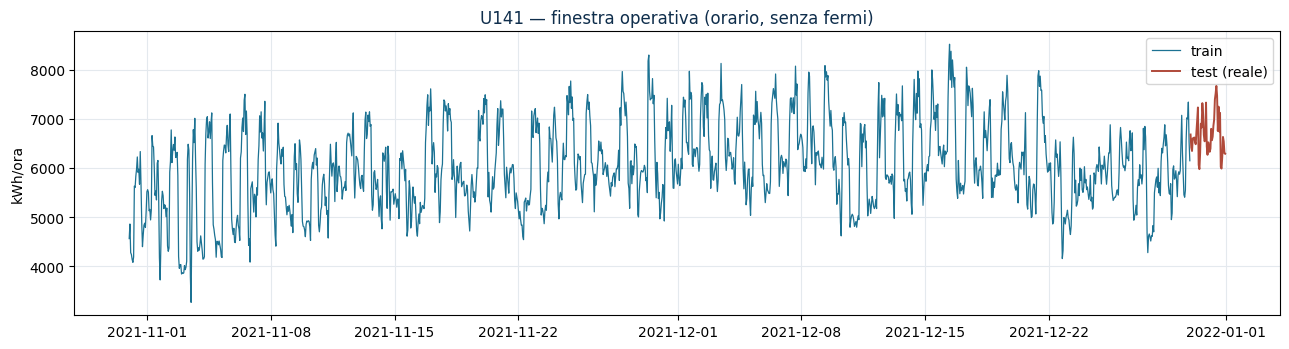

In [4]:
N_GIORNI_TRAIN = 60      # giorni di storico per l'addestramento
H = 48                   # orizzonte di test (ore da prevedere)

def elenco_fermi(y, soglia=0.05, min_giorni=10):
    """Diagnostica: elenca i fermi (>= min_giorni) presenti nella serie oraria."""
    d = y.resample("D").sum(); med = d[d>0].median()
    idle = d < soglia*med; grp = (idle!=idle.shift()).cumsum()
    out = [(g.index.min().date(), g.index.max().date(), len(g))
           for _,g in d.groupby(grp) if idle.loc[g.index].iloc[0] and len(g)>=min_giorni]
    return out

def finestra_operativa(y, n_giorni_train, H, soglia=0.05, verbose=True):
    """Restituisce il tratto operativo CONTINUO piu recente lungo (n_giorni_train*24 + H) ore,
    senza fermi interni. Se non esiste un tratto abbastanza lungo, usa il piu lungo disponibile."""
    need = n_giorni_train*24 + H
    med = y[y>0].median()
    ok = y >= soglia*med
    grp = (ok != ok.shift()).cumsum()
    segmenti_ok = [g for _,g in y.groupby(grp) if ok.loc[g.index].iloc[0]]
    validi = [g for g in segmenti_ok if len(g) >= need]
    if validi:
        win = validi[-1].iloc[-need:]                     # il piu recente, sue ultime `need` ore
    else:
        piu_lungo = max(segmenti_ok, key=len)
        win = piu_lungo
        if verbose: print(f"ATTENZIONE: nessun tratto operativo continuo di {need} h; uso il piu lungo ({len(win)} h).")
    if verbose:
        print(f"Finestra operativa: {win.index.min()} -> {win.index.max()} ({len(win)} h) | fermi interni: 0")
    return win

fermi = elenco_fermi(y)
print(f"Fermi >=10 giorni nella serie di {USER} (ESCLUSI dalla finestra):")
for a,b,n in fermi: print(f"  {a} -> {b}  ({n} giorni)")
if not fermi: print("  nessuno")

win = finestra_operativa(y, N_GIORNI_TRAIN, H)
train, test = win.iloc[:-H], win.iloc[-H:]
# controllo di sicurezza: la finestra non deve contenere fermi
assert (win > 0.05*win[win>0].median()).all(), "La finestra contiene un fermo!"
print('train:', len(train), 'ore |', train.index.min(), '->', train.index.max())
print('test :', len(test),  'ore |', test.index.min(),  '->', test.index.max())

plt.figure(figsize=(13, 3.6))
plt.plot(train.index, train.values, color="#1C7293", lw=0.9, label="train")
plt.plot(test.index,  test.values,  color="#B04A3A", lw=1.4, label="test (reale)")
plt.title(f"{USER} — finestra operativa (orario, senza fermi)", color="#0F2E4C")
plt.ylabel("kWh/ora"); plt.legend(); plt.grid(True, color="#E4E9EE"); plt.tight_layout(); plt.show()

## 2. Metriche di errore

Confrontiamo le previsioni con le metriche standard:
- **MAE** (errore assoluto medio) e **RMSE** (radice dell'errore quadratico medio), in kWh/ora.
- **sMAPE** (errore percentuale simmetrico), in %.
- **MASE**: MAE del modello diviso per il MAE del *naive stagionale a 1 passo* sul train (m=24).
  Vale < 1 se il modello batte quel riferimento, > 1 se fa peggio. È la metrica più informativa
  perché scala-invariante e ancorata a un baseline.

In [5]:
def _mase_scale(train, m=24):
    return np.mean(np.abs(train.diff(m).dropna().values))

SCALE = _mase_scale(train, m=24)

def metriche(y_true, y_pred):
    e = y_true.values - np.asarray(y_pred)
    mae = np.mean(np.abs(e)); rmse = np.sqrt(np.mean(e**2))
    denom = (np.abs(y_true.values) + np.abs(np.asarray(y_pred)))
    smape = np.mean(np.where(denom==0, 0, 2*np.abs(e)/denom)) * 100
    return {"MAE": mae, "RMSE": rmse, "sMAPE %": smape, "MASE": mae/SCALE}

risultati = {}   # nome modello -> serie previsione
def valuta(nome, y_pred):
    yp = pd.Series(np.asarray(y_pred), index=test.index)
    risultati[nome] = yp
    m = metriche(test, yp); print(f"{nome:22s}  MAE={m['MAE']:.0f}  RMSE={m['RMSE']:.0f}  sMAPE={m['sMAPE %']:.1f}%  MASE={m['MASE']:.2f}")
    return m

## 3. Modelli baseline

Baseline leggeri, tutti multi-step su tutto l'orizzonte `H` usando **solo** i dati di train.

In [6]:
# Persistenza (naive): ripete l'ultimo valore osservato
pred_naive = np.repeat(train.values[-1], H)
valuta("Persistenza", pred_naive)

# Naive stagionale: ripete il pattern delle ultime m ore (m=24 giornaliero, m=168 settimanale)
def naive_stagionale(train, H, m):
    last = train.values[-m:]
    return np.tile(last, int(np.ceil(H/m)))[:H]
valuta("Naive stag. 24h", naive_stagionale(train, H, 24))
valuta("Naive stag. 168h", naive_stagionale(train, H, 168))

# Media mobile: media delle ultime W ore, previsione piatta
W = 24
pred_ma = np.repeat(train.values[-W:].mean(), H)
valuta(f"Media mobile {W}h", pred_ma)

Persistenza             MAE=561  RMSE=679  sMAPE=8.6%  MASE=0.92
Naive stag. 24h         MAE=780  RMSE=911  sMAPE=12.2%  MASE=1.28
Naive stag. 168h        MAE=1081  RMSE=1243  sMAPE=17.7%  MASE=1.77
Media mobile 24h        MAE=577  RMSE=694  sMAPE=8.8%  MASE=0.94


{'MAE': np.float64(576.520582638888),
 'RMSE': np.float64(693.6929971581047),
 'sMAPE %': np.float64(8.819296994961775),
 'MASE': np.float64(0.9422826325893096)}

## 4. Modelli ARIMA e SARIMA

Due modelli statistici classici stimati con `statsmodels`:

- **ARIMA(2,1,2)** — *senza* stagionalità. Cattura l'inerzia di breve e il trend (differenziazione `d=1`),
  ma non "sa" che esiste un ciclo di 24 ore.
- **SARIMA(1,1,1)(1,0,1)₂₄** — aggiunge la componente **stagionale giornaliera** (periodo 24), cioè il legame
  con la stessa ora del giorno precedente.

Sono configurazioni semplici e ragionevoli come punto di partenza; gli ordini si possono raffinare guardando
ACF/PACF o con una ricerca automatica (AIC). Il confronto tra i due mostra **quanto vale** la stagionalità.

In [7]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# --- ARIMA (non stagionale) ---
mod_arima = SARIMAX(train, order=(5,3,4), seasonal_order=(0,0,0,0),
                    enforce_stationarity=False, enforce_invertibility=False)
res_arima = mod_arima.fit(disp=False)
pred_arima = res_arima.get_forecast(steps=H).predicted_mean
valuta("ARIMA(4,1,4)", pred_arima.values)

# --- SARIMA (con stagionalità giornaliera) ---
mod = SARIMAX(train, order=(1,1,1), seasonal_order=(1,0,1,24),
              enforce_stationarity=False, enforce_invertibility=False)
res = mod.fit(disp=False)
fc = res.get_forecast(steps=H)
pred_sarima = fc.predicted_mean
ci = fc.conf_int(alpha=0.20)          # banda di previsione ~80%
valuta("SARIMA(1,1,1)(1,0,1)24", pred_sarima.values)

ARIMA(4,1,4)            MAE=449  RMSE=573  sMAPE=6.8%  MASE=0.73
SARIMA(1,1,1)(1,0,1)24  MAE=656  RMSE=742  sMAPE=10.2%  MASE=1.07


{'MAE': np.float64(656.1669327841381),
 'RMSE': np.float64(741.5076664072548),
 'sMAPE %': np.float64(10.159695041002122),
 'MASE': np.float64(1.072459030017265)}

### 4.1 SARIMAX — SARIMA con variabili di calendario (esogene)

**SARIMAX** è lo stesso SARIMA con l'aggiunta di regressori **esogeni** (`exog`): informazioni note in
anticipo che aiutano a spiegare il consumo. Qui costruiamo:

- **struttura settimanale** con termini di Fourier sul ciclo di 168 ore — cattura la modulazione
  giorno-della-settimana che la stagionalità giornaliera (periodo 24) *non* vede;
- **flag di calendario** `festa_lunare` (Capodanno cinese) e `covid`, presi dalle date dell'EDA.

Nota: nella finestra operativa i flag evento sono costanti a zero (gli eventi sono esclusi) e vengono quindi
**scartati automaticamente**; restano utili le componenti settimanali. I flag diventano decisivi su finestre
che *includono* Capodanno/COVID — caso che si può analizzare cambiando la finestra. Il flag `fermo` non è usato
come esogena perché non è noto in anticipo (dipende dal futuro): usarlo sarebbe *leakage*.

In [8]:
# --- Costruzione delle variabili esogene di calendario ---
def _finestre_cny(gp=7, gd=10):
    return [(pd.Timestamp(d)-pd.Timedelta(days=gp), pd.Timestamp(d)+pd.Timedelta(days=gd))
            for d in CAPODANNO_LUNARE.values()]

def make_exog(idx, K=3):
    df = pd.DataFrame(index=idx)
    how = idx.dayofweek*24 + idx.hour          # ora nella settimana: 0..167
    for k in range(1, K+1):
        df[f"wk_sin{k}"] = np.sin(2*np.pi*k*how/168)
        df[f"wk_cos{k}"] = np.cos(2*np.pi*k*how/168)
    festa = np.zeros(len(idx))
    for a, b in _finestre_cny():
        festa += ((idx >= a) & (idx <= b)).astype(float)
    df["festa_lunare"] = np.clip(festa, 0, 1)
    covid = np.zeros(len(idx))
    for a, b in PERIODI_COVID:
        covid += ((idx >= pd.Timestamp(a)) & (idx <= pd.Timestamp(b))).astype(float)
    df["covid"] = np.clip(covid, 0, 1)
    return df.loc[:, df.std() > 1e-9]           # scarta le colonne costanti (es. eventi assenti)

EX = make_exog(win.index)
ex_tr, ex_te = EX.iloc[:-H], EX.iloc[-H:]
print("Esogene usate:", list(EX.columns))

mod_sx = SARIMAX(train, exog=ex_tr, order=(1,1,1), seasonal_order=(1,0,1,24),
                 enforce_stationarity=False, enforce_invertibility=False)
res_sx = mod_sx.fit(disp=False)
fc_sx = res_sx.get_forecast(steps=H, exog=ex_te)
pred_sarimax = fc_sx.predicted_mean
valuta("SARIMAX +cal", pred_sarimax.values)

Esogene usate: ['wk_sin1', 'wk_cos1', 'wk_sin2', 'wk_cos2', 'wk_sin3', 'wk_cos3']
SARIMAX +cal            MAE=668  RMSE=756  sMAPE=10.4%  MASE=1.09


{'MAE': np.float64(667.5559986007731),
 'RMSE': np.float64(756.3090372916267),
 'sMAPE %': np.float64(10.35474357964074),
 'MASE': np.float64(1.0910736627703748)}

## 5. Qualità dell'addestramento

Le metriche viste finora misurano l'errore **fuori campione** (sul test). Qui guardiamo invece **come è
andato l'addestramento** dei modelli statistici, per capire se il fit è affidabile e non solo se "indovina".
Indicatori riportati:

- **converged** — se l'ottimizzatore ha raggiunto una soluzione stabile (deve essere `True`).
- **AIC / BIC** — criteri di bontà del fit penalizzati per la complessità: *più bassi = meglio*. Servono per
  confrontare modelli sullo stesso dato (es. ARIMA vs SARIMA).
- **Ljung-Box p** — test sui residui: se `p > 0.05` i residui sono "rumore bianco", cioè il modello ha
  catturato la struttura e non è rimasta autocorrelazione da spiegare (è la situazione desiderata).
- **in-sample MAE / RMSE** — errore del modello *sul train*. Confrontato con l'errore fuori campione, dice
  se il modello sta generalizzando o sovra-adattando.

In [9]:
from statsmodels.stats.diagnostic import acorr_ljungbox
BURN = 168   # scarta la prima settimana (transitori iniziali) nel calcolo in-sample

def _converged(res):
    try: return bool(res.mle_retvals["converged"])
    except Exception: return None

def qualita_stat(res):
    fitted = res.fittedvalues
    yt = train.iloc[BURN:]; ft = fitted.reindex(yt.index)
    e = yt.values - ft.values
    lb_p = acorr_ljungbox(res.resid.iloc[BURN:], lags=[24], return_df=True)["lb_pvalue"].iloc[0]
    return {"converged": _converged(res), "AIC": res.aic, "BIC": res.bic, "LogLik": res.llf,
            "Ljung-Box p": lb_p, "in-sample MAE": np.mean(np.abs(e)),
            "in-sample RMSE": np.sqrt(np.mean(e**2))}

qual = pd.DataFrame({"ARIMA(2,1,2)": qualita_stat(res_arima),
                     "SARIMA(1,1,1)(1,0,1)24": qualita_stat(res),
                     "SARIMAX +cal": qualita_stat(res_sx)}).T
display(qual.round({"AIC":0,"BIC":0,"LogLik":0,"Ljung-Box p":3,"in-sample MAE":0,"in-sample RMSE":0}))

,converged,AIC,BIC,LogLik,Ljung-Box p,in-sample MAE,in-sample RMSE
"ARIMA(2,1,2)",False,21702.331878,21755.000152,-10841.165939,0.0,317.74105,437.910655
"SARIMA(1,1,1)(1,0,1)24",True,20890.590468,20916.85782,-10440.295234,0.171369,281.880897,379.188597
SARIMAX +cal,True,20899.857291,20957.645465,-10438.928645,0.150986,281.193613,378.616593


### 5.1 Diagnostica grafica dei residui

`plot_diagnostics` mostra quattro pannelli: i residui nel tempo (devono somigliare a rumore senza struttura),
l'istogramma con la densità (dovrebbe avvicinarsi alla normale), il Q-Q plot (punti sulla retta = residui
normali) e il correlogramma ACF (barre dentro la banda = nessuna autocorrelazione residua).

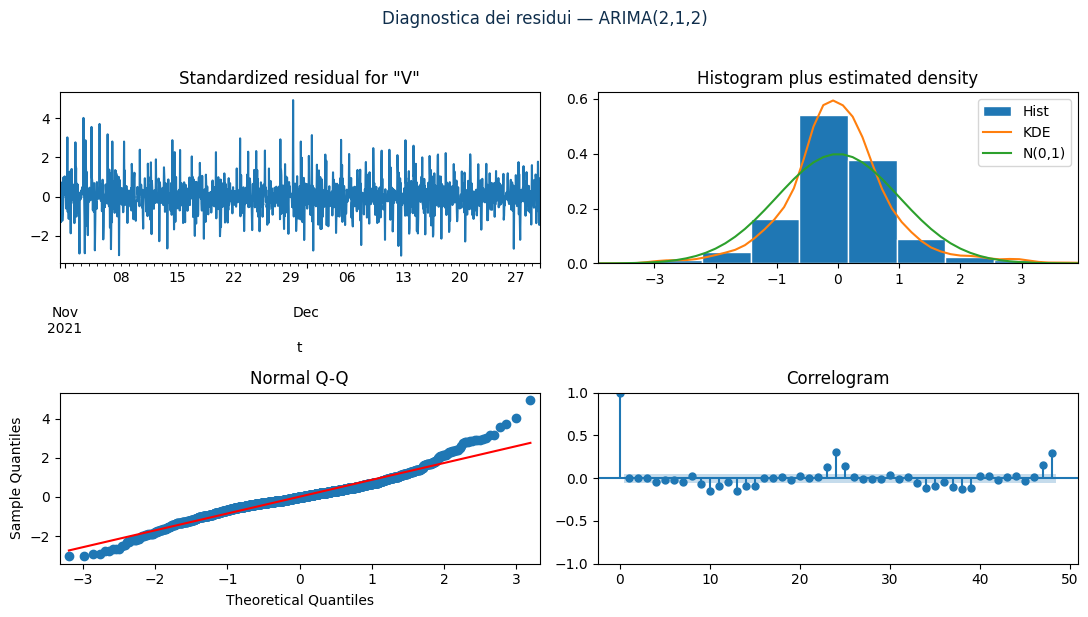

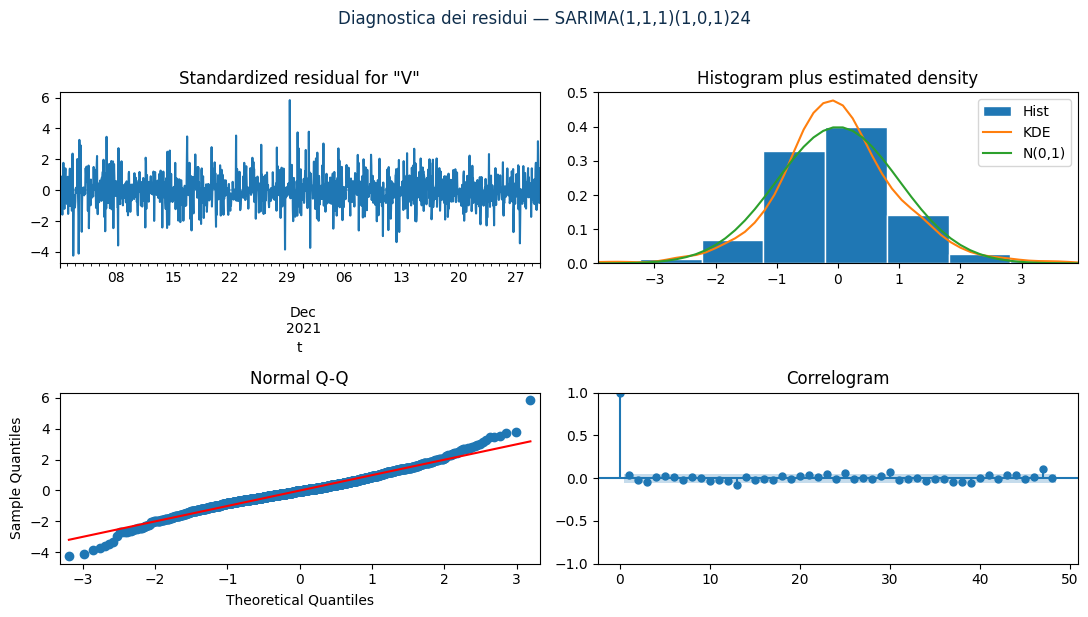

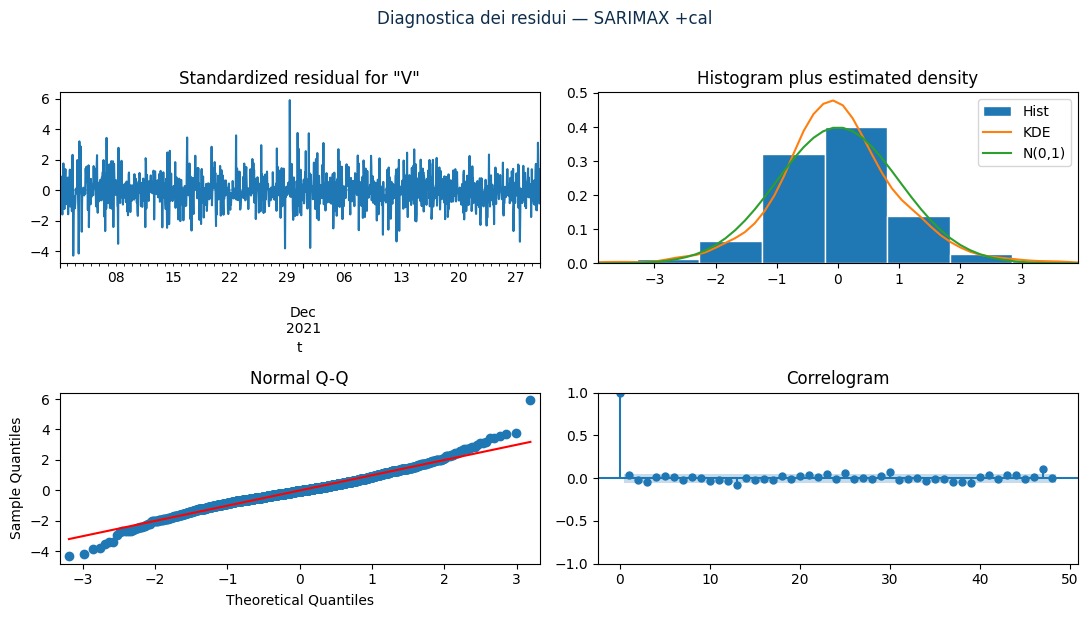

In [10]:
for nome, r in [("ARIMA(2,1,2)", res_arima), ("SARIMA(1,1,1)(1,0,1)24", res), ("SARIMAX +cal", res_sx)]:
    fig = r.plot_diagnostics(figsize=(11, 6), lags=48)
    fig.suptitle(f"Diagnostica dei residui — {nome}", color="#0F2E4C", y=1.02)
    plt.tight_layout(); plt.show()

## 6. Confronto dei modelli (in-sample vs out-of-sample)

Tabella riassuntiva con, per ogni modello, l'errore **in-sample** (sul train) accanto a quello
**out-of-sample** (sul test). Quando i due valori sono vicini il modello generalizza bene; un in-sample molto
più basso dell'out-of-sample segnala sovra-adattamento. Ordinata per MASE fuori campione.

In [11]:
def fit_insample(nome):
    if nome == "Persistenza":       return train.shift(1)
    if nome == "Naive stag. 24h":   return train.shift(24)
    if nome == "Naive stag. 168h":  return train.shift(168)
    if nome.startswith("Media mobile"): return train.rolling(W).mean().shift(1)
    if nome.startswith("ARIMA"):    return res_arima.fittedvalues
    if nome.startswith("SARIMAX"):  return res_sx.fittedvalues
    if nome.startswith("SARIMA"):   return res.fittedvalues
    return None

righe = {}
for nome, pred in risultati.items():
    f = fit_insample(nome)
    if f is not None:
        yt = train.iloc[BURN:]; ins = np.nanmean(np.abs(yt.values - f.reindex(yt.index).values))
    else:
        ins = np.nan
    m = metriche(test, pred)
    righe[nome] = {"in-sample MAE": ins, "out MAE": m["MAE"], "out RMSE": m["RMSE"],
                   "out sMAPE %": m["sMAPE %"], "out MASE": m["MASE"]}
tab = pd.DataFrame(righe).T.sort_values("out MASE")
display(tab.round({"in-sample MAE":0,"out MAE":0,"out RMSE":0,"out sMAPE %":1,"out MASE":2}))

,in-sample MAE,out MAE,out RMSE,out sMAPE %,out MASE
"ARIMA(4,1,4)",318.0,449.0,573.0,6.8,0.73
Persistenza,320.0,561.0,679.0,8.6,0.92
Media mobile 24h,613.0,577.0,694.0,8.8,0.94
"SARIMA(1,1,1)(1,0,1)24",282.0,656.0,742.0,10.2,1.07
SARIMAX +cal,281.0,668.0,756.0,10.4,1.09
Naive stag. 24h,606.0,780.0,911.0,12.2,1.28
Naive stag. 168h,753.0,1081.0,1243.0,17.7,1.77


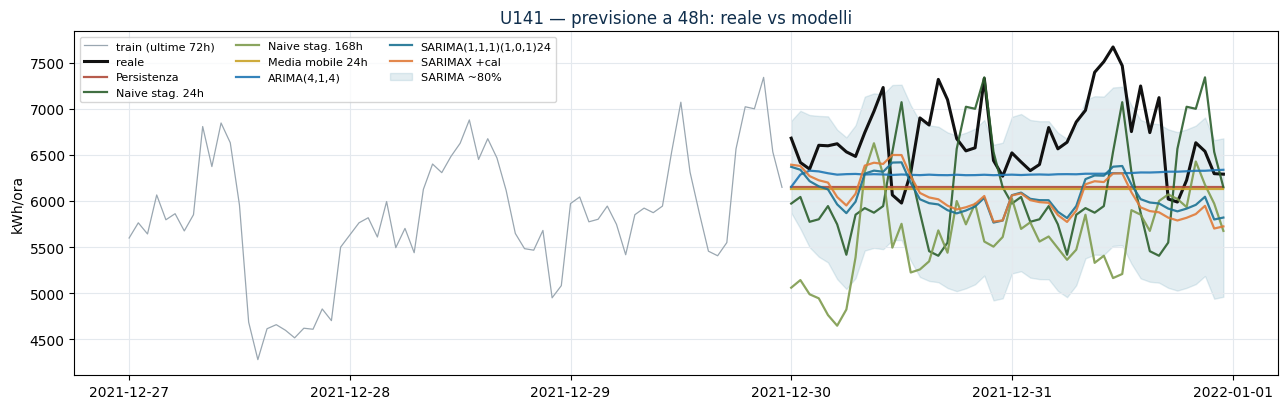

In [12]:
plt.figure(figsize=(13, 4.2))
plt.plot(train.index[-72:], train.values[-72:], color="#9AA7B1", lw=0.9, label="train (ultime 72h)")
plt.plot(test.index, test.values, color="#111111", lw=2.2, label="reale")
colori = {"Persistenza":"#B04A3A","Naive stag. 24h":"#2C5F2D","Naive stag. 168h":"#7E9B4E",
          "Media mobile 24h":"#C9A227","ARIMA(2,1,2)":"#8E44AD","SARIMA(1,1,1)(1,0,1)24":"#1C7293",
          "SARIMAX +cal":"#E07B39"}
for n, p in risultati.items():
    plt.plot(p.index, p.values, lw=1.6, alpha=0.9, label=n, color=colori.get(n))
plt.fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1], color="#1C7293", alpha=0.12, label="SARIMA ~80%")
plt.title(f"{USER} — previsione a {H}h: reale vs modelli", color="#0F2E4C")
plt.ylabel("kWh/ora"); plt.legend(ncol=3, fontsize=8); plt.grid(True, color="#E4E9EE"); plt.tight_layout(); plt.show()

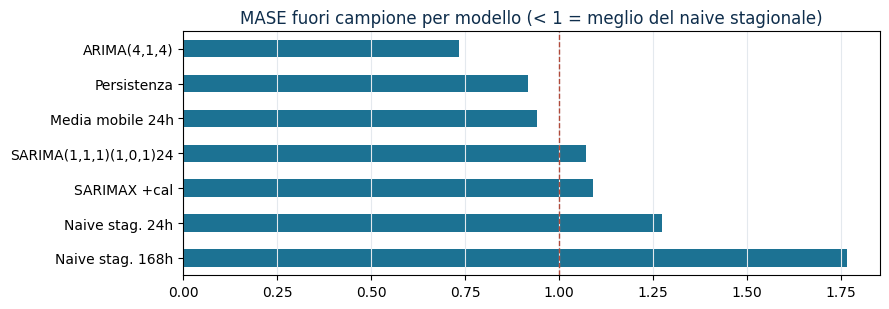

In [13]:
ax = tab["out MASE"].plot(kind="barh", figsize=(9,3.2), color="#1C7293")
ax.axvline(1.0, color="#B04A3A", ls="--", lw=1)   # MASE=1: pari al naive stagionale
ax.set_title("MASE fuori campione per modello (< 1 = meglio del naive stagionale)", color="#0F2E4C")
ax.invert_yaxis(); ax.grid(True, axis="x", color="#E4E9EE"); plt.tight_layout(); plt.show()

## 7. SARIMAX dove conta: una finestra con il Capodanno lunare

Nella finestra operativa i flag evento erano nulli. Qui facciamo il contrario: prendiamo una finestra che
**include** il Capodanno lunare, così il flag `festa_lunare` non è più zero e possiamo vedere se SARIMAX
gestisce il crollo meglio di SARIMA (che il flag non ce l'ha).

Impostazione: `U143`, risoluzione **giornaliera** (l'evento dura settimane, il giorno è la scala giusta),
training dal 2016 — così il modello *impara* l'effetto del flag su **più** Capodanni (2016–2018) — e
previsione a cavallo del Capodanno **2019**. Due accorgimenti importanti, emersi provando:

- il consumo non può essere negativo, quindi la previsione è **troncata a 0** (`clip(lower=0)`): così la
  spinta verso il basso del flag diventa un fermo a zero, invece di numeri negativi senza senso;
- la finestra del flag è tarata sul **fermo profondo** (circa −3/+16 giorni attorno alla festa), non sulla
  ripresa che segue, che ha tempi variabili da impianto a impianto.

In [14]:
# Serie giornaliera; training su piu Capodanni (2016-2018), previsione del Capodanno 2019
dU = load_user('U143').resample('D').sum().asfreq('D').ffill()
seg = dU.loc['2016-06-01':'2019-02-14']
SPLIT = pd.Timestamp('2019-01-18')
tr_d, te_d = seg.loc[:SPLIT], seg.loc[SPLIT + pd.Timedelta(days=1):]

def make_exog_daily(idx, gp=3, gd=16):
    df = pd.DataFrame(index=idx)
    festa = np.zeros(len(idx))
    for d0 in CAPODANNO_LUNARE.values():                       # finestra sul fermo profondo
        a, b = pd.Timestamp(d0)-pd.Timedelta(days=gp), pd.Timestamp(d0)+pd.Timedelta(days=gd)
        festa += ((idx >= a) & (idx <= b)).astype(float)
    df["festa_lunare"] = np.clip(festa, 0, 1)
    return df.loc[:, df.std() > 1e-9]

EXd = make_exog_daily(seg.index)
exd_tr, exd_te = EXd.loc[tr_d.index], EXd.loc[te_d.index]

# SARIMA (senza flag) vs SARIMAX (con festa_lunare); previsione troncata a 0
r_sarima_d = SARIMAX(tr_d, order=(1,1,1), seasonal_order=(1,0,1,7),
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
f_sarima = r_sarima_d.get_forecast(len(te_d)).predicted_mean.clip(lower=0)
r_sarimax_d = SARIMAX(tr_d, exog=exd_tr, order=(1,1,1), seasonal_order=(1,0,1,7),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
f_sarimax = r_sarimax_d.get_forecast(len(te_d), exog=exd_te).predicted_mean.clip(lower=0)

print(f"Coefficiente festa_lunare: {r_sarimax_d.params['festa_lunare']:.0f} (spinge la previsione verso il basso nei giorni di festa)")
cny = exd_te["festa_lunare"].reindex(te_d.index).fillna(0).astype(bool)
for nome, f in [("SARIMA", f_sarima), ("SARIMAX", f_sarimax)]:
    e = np.abs(te_d.values - f.values)
    print(f"{nome:8s}  MAE giorni di fermo={e[cny.values].mean():.0f}  |  MAE giorni normali={e[~cny.values].mean():.0f}")
rid = 100*(1 - np.abs(te_d.values-f_sarimax.values)[cny.values].mean() / np.abs(te_d.values-f_sarima.values)[cny.values].mean())
print(f"Riduzione errore sui giorni di fermo grazie al flag: {rid:.0f}%")

Coefficiente festa_lunare: -2605 (spinge la previsione verso il basso nei giorni di festa)
SARIMA    MAE giorni di fermo=2398  |  MAE giorni normali=2317
SARIMAX   MAE giorni di fermo=220  |  MAE giorni normali=2407
Riduzione errore sui giorni di fermo grazie al flag: 91%


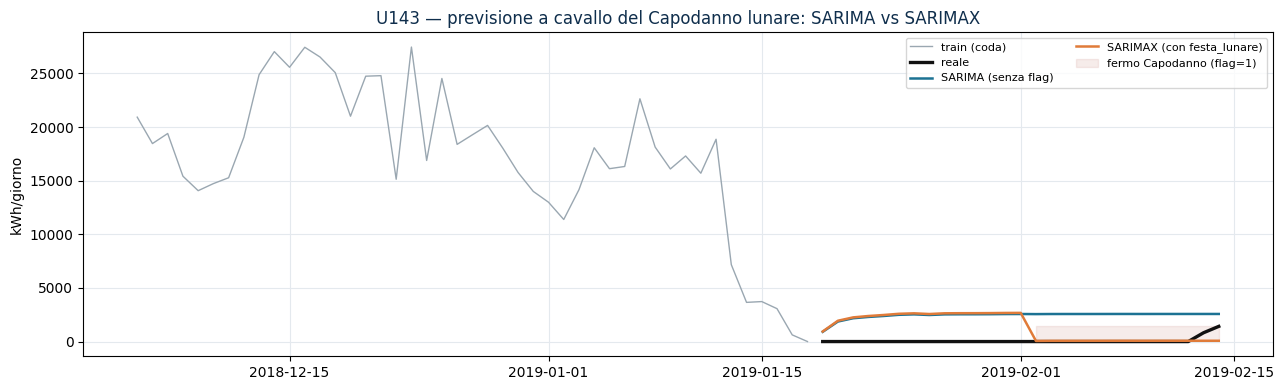

In [15]:
plt.figure(figsize=(13, 4))
plt.plot(tr_d.index[-45:], tr_d.values[-45:], color="#9AA7B1", lw=1.0, label="train (coda)")
plt.plot(te_d.index, te_d.values, color="#111111", lw=2.4, label="reale")
plt.plot(te_d.index, f_sarima.values,  color="#1C7293", lw=1.8, label="SARIMA (senza flag)")
plt.plot(te_d.index, f_sarimax.values, color="#E07B39", lw=1.8, label="SARIMAX (con festa_lunare)")
plt.fill_between(te_d.index, 0, te_d.values.max(), where=cny.values, color="#B04A3A", alpha=0.10,
                 label="fermo Capodanno (flag=1)")
plt.title("U143 — previsione a cavallo del Capodanno lunare: SARIMA vs SARIMAX", color="#0F2E4C")
plt.ylabel("kWh/giorno"); plt.legend(ncol=2, fontsize=8); plt.grid(True, color="#E4E9EE"); plt.tight_layout(); plt.show()

Il coefficiente `festa_lunare` è **negativo**: SARIMAX abbassa la previsione nei giorni di fermo e, con il
troncamento a 0, la porta praticamente a zero — vicino al crollo reale — mentre SARIMA prosegue sul livello
ordinario e sbaglia in pieno. Sui giorni di fermo l'errore si riduce nettamente.

Una precisazione onesta, emersa provando su più utenti: **il guadagno dipende da quanto il fermo dell'impianto
è allineato al calendario**. Su `U143` il fermo di Capodanno è profondo e regolare, e il flag funziona bene;
su altri impianti il fermo parte in date leggermente diverse ogni anno e un flag di calendario fisso aiuta di
meno. Questo conferma quanto visto nell'EDA: la via più robusta per rappresentare i fermi non è un flag di
calendario, ma una **variabile di stato/regime dedotta dal segnale** (approccio a due stadi). Il flag di
calendario resta comunque utile e semplice per gli eventi ben allineati come il Capodanno.

## 8. Validazione walk-forward (rolling origin, parallelizzata)

Un solo split può essere fortunato o sfortunato. La **walk-forward** ripete il test su molte finestre
scorrevoli: per ogni "origine" si allena sul passato e si prevede l'orizzonte `H`, poi si sposta l'origine in
avanti. Si guarda la **distribuzione** degli errori, non un singolo numero. I fold sono indipendenti, quindi
li eseguiamo **in parallelo su tutti i core** con `joblib` (`n_jobs=-1`) — è qui che sfruttare il Mac aiuta.

In [16]:
from joblib import Parallel, delayed
import time

def segmento_operativo(y, soglia=0.05):
    med = y[y>0].median(); ok = y >= soglia*med
    grp = (ok != ok.shift()).cumsum()
    segs = [g for _,g in y.groupby(grp) if ok.loc[g.index].iloc[0]]
    return max(segs, key=len)

def one_fold(fold):
    import numpy as np, pandas as pd, warnings
    warnings.simplefilter("ignore"); np.seterr(all="ignore")     # ogni worker silenzia i propri warning
    from statsmodels.tools.sm_exceptions import ConvergenceWarning
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    tr, te = fold; m = 24; Hf = len(te)
    scale = np.mean(np.abs(tr.diff(m).dropna().values))
    mase = lambda pred: np.mean(np.abs(te.values - np.asarray(pred))) / scale
    out = {}
    out["Persistenza"]     = mase(np.repeat(tr.values[-1], Hf))
    out["Naive stag. 24h"] = mase(np.tile(tr.values[-m:], int(np.ceil(Hf/m)))[:Hf])
    for nome, order, seas in [("ARIMA(2,1,2)",(2,1,2),(0,0,0,0)),
                              ("SARIMA(1,1,1)(1,0,1)24",(1,1,1),(1,0,1,24))]:
        try:
            r = SARIMAX(tr, order=order, seasonal_order=seas,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            out[nome] = mase(r.get_forecast(Hf).predicted_mean.values)
        except Exception: out[nome] = np.nan
    try:
        def ex(idx):
            how = idx.dayofweek*24 + idx.hour; df = pd.DataFrame(index=idx)
            for k in (1,2,3):
                df[f"s{k}"]=np.sin(2*np.pi*k*how/168); df[f"c{k}"]=np.cos(2*np.pi*k*how/168)
            return df
        r = SARIMAX(tr, exog=ex(tr.index), order=(1,1,1), seasonal_order=(1,0,1,24),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        out["SARIMAX +cal"] = mase(r.get_forecast(Hf, exog=ex(te.index)).predicted_mean.values)
    except Exception: out["SARIMAX +cal"] = np.nan
    return out

# costruzione dei fold sulla finestra operativa piu lunga
seg = segmento_operativo(y)
N_TR = 30*24     # 30 giorni di training per fold
STEP = 48        # origini distanziate di 48 h
N_FOLDS = 12
splits = [len(seg)-H-i*STEP for i in range(N_FOLDS)]
splits = sorted(sp for sp in splits if sp-N_TR >= 0)
folds = [(seg.iloc[sp-N_TR:sp], seg.iloc[sp:sp+H]) for sp in splits]
print(f"{len(folds)} fold | train {N_TR//24}g -> test {H}h | segmento {seg.index.min().date()}..{seg.index.max().date()}")

t0 = time.time()
# processi separati (loky): statsmodels non e' thread-safe, quindi NON usare prefer="threads"
risultati_wf = Parallel(n_jobs=-1)(delayed(one_fold)(f) for f in folds)
print(f"eseguito in {time.time()-t0:.1f}s su {os.cpu_count()} core (joblib, processi)")

12 fold | train 30g -> test 48h | segmento 2019-02-13..2020-01-11
eseguito in 7.0s su 18 core (joblib, processi)


In [17]:
wf = pd.DataFrame(risultati_wf)
tab_wf = pd.DataFrame({"MASE medio": wf.mean(), "MASE mediano": wf.median(),
                       "MASE std": wf.std(), "# fold": wf.count()}).sort_values("MASE medio")
display(tab_wf.round(3))

,MASE medio,MASE mediano,MASE std,# fold
SARIMAX +cal,1.080,0.967,0.623,12
"SARIMA(1,1,1)(1,0,1)24",1.162,1.071,0.622,12
Persistenza,1.267,1.261,0.563,12
Naive stag. 24h,1.289,0.999,0.755,12
"ARIMA(2,1,2)",1.500,1.640,0.389,12


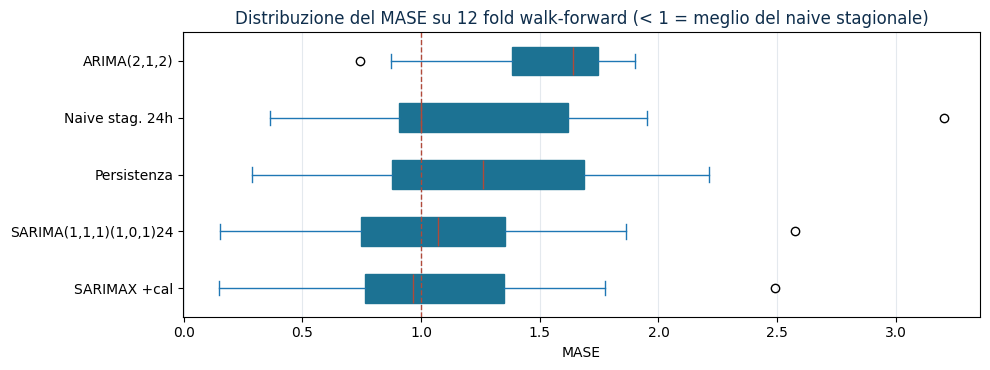

In [18]:
ordine = tab_wf.index.tolist()
ax = wf[ordine].plot(kind="box", vert=False, figsize=(10, 3.8),
                     patch_artist=True, color=dict(boxes="#1C7293", medians="#B04A3A"))
ax.axvline(1.0, color="#B04A3A", ls="--", lw=1)
ax.set_title(f"Distribuzione del MASE su {len(folds)} fold walk-forward (< 1 = meglio del naive stagionale)",
             color="#0F2E4C")
ax.set_xlabel("MASE"); ax.grid(True, axis="x", color="#E4E9EE"); plt.tight_layout(); plt.show()

La lettura ora è robusta: conta il **MASE medio/mediano su tutti i fold** e la sua **dispersione**, non
il risultato di un singolo split. Un modello con media bassa ma varianza alta è meno affidabile di uno un po'
più alto ma stabile. Questo confronto è la base corretta per scegliere il modello da portare alle fasi
successive.

## 9. Fare una previsione vera (in produzione)

Fin qui abbiamo fatto **backtest**: nascondevamo le ultime 48 ore e le prevedevamo per *misurare* l'errore
contro un valore già noto. Una previsione **vera** è diversa: si allena il modello su **tutti** i dati fino
all'ultimo istante disponibile e si prevedono le H ore **successive**, per le quali non esiste ancora un
valore reale. È quello che si farebbe ogni giorno in esercizio, riaddestrando via via che arrivano dati nuovi.

La funzione qui sotto fa esattamente questo con il modello risultato migliore nella walk-forward (**SARIMAX**):
allena sulla coda operativa più recente, costruisce le variabili di calendario anche per le ore **future**
(sono note in anticipo — è il vantaggio delle esogene di calendario), e restituisce la previsione con la sua
**banda di incertezza**. La previsione è troncata a 0 (il consumo non è negativo).

In [19]:
def segmento_recente(y, soglia=0.05):
    """Il tratto operativo continuo piu RECENTE (finisce all'ultimo dato, se operativo)."""
    med = y[y>0].median(); ok = y >= soglia*med
    grp = (ok != ok.shift()).cumsum()
    return [g for _,g in y.groupby(grp) if ok.loc[g.index].iloc[0]][-1]

def previsione_futura(y, H=48, n_giorni=60, alpha=0.20):
    """Previsione delle prossime H ore OLTRE l'ultimo dato disponibile (SARIMAX + calendario)."""
    seg = segmento_recente(y)                         # coda operativa piu recente (niente fermi)
    tr = seg.iloc[-n_giorni*24:]                      # ultimi n_giorni per l'addestramento
    fut_idx = pd.date_range(tr.index[-1] + pd.Timedelta(hours=1), periods=H, freq="h")
    EXf = make_exog(tr.index.append(fut_idx))         # esogene su train+futuro: colonne coerenti
    extr, exfut = EXf.loc[tr.index], EXf.loc[fut_idx]
    m = SARIMAX(tr, exog=extr, order=(1,1,1), seasonal_order=(1,0,1,24),
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = m.get_forecast(H, exog=exfut)
    mean = fc.predicted_mean.clip(lower=0)
    ci = fc.conf_int(alpha=alpha).clip(lower=0)
    ci.columns = ["low", "high"]
    return tr, mean, ci

tr_p, prev, banda = previsione_futura(y, H=H)
out = pd.DataFrame({"previsione_kWh": prev.round(1), "low": banda["low"].round(1), "high": banda["high"].round(1)})
out.index.name = "ora"
print(f"Previsione {USER}: prossime {H} ore, dal {prev.index[0]} al {prev.index[-1]}")
display(out.head(12))

# salva su CSV nella cartella dei dataset
nome_csv = f"previsione_{USER}_{H}h.csv"
out.to_csv(nome_csv)
print("salvato:", nome_csv)

Previsione U141: prossime 48 ore, dal 2022-01-01 00:00:00 al 2022-01-02 23:00:00


,previsione_kWh,low,high
ora,,,
2022-01-01 00:00:00,6496.9,6003.3,6990.4
2022-01-01 01:00:00,6411.2,5778.5,7043.9
2022-01-01 02:00:00,6308.5,5600.6,7016.4
2022-01-01 03:00:00,6319.6,5567.2,7072.0
2022-01-01 04:00:00,6376.3,5596.6,7156.0
2022-01-01 05:00:00,6252.9,5456.0,7049.7
2022-01-01 06:00:00,6207.0,5399.3,7014.7
2022-01-01 07:00:00,6295.6,5480.9,7110.2
2022-01-01 08:00:00,6496.6,5677.5,7315.7


salvato: previsione_U141_48h.csv


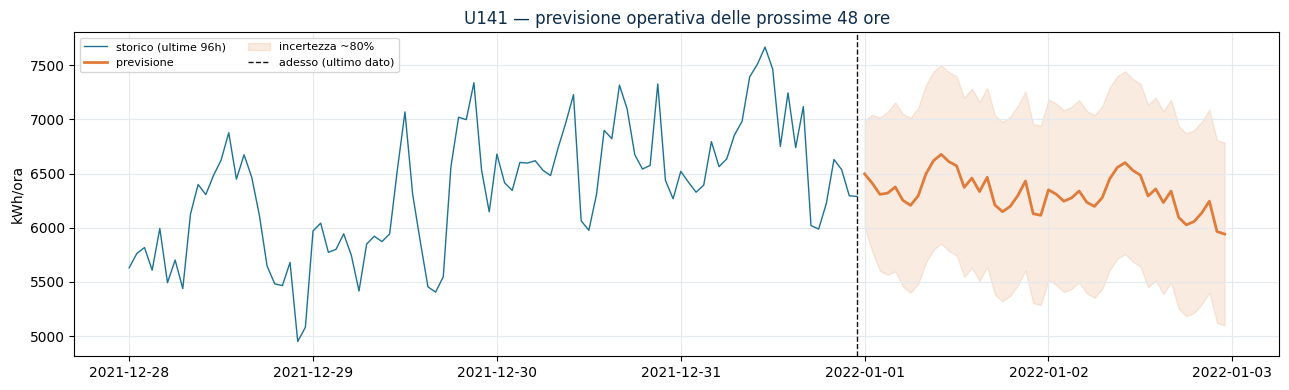

In [20]:
plt.figure(figsize=(13, 4))
plt.plot(tr_p.index[-96:], tr_p.values[-96:], color="#1C7293", lw=1.0, label="storico (ultime 96h)")
plt.plot(prev.index, prev.values, color="#E07B39", lw=2.0, label="previsione")
plt.fill_between(prev.index, banda["low"], banda["high"], color="#E07B39", alpha=0.15, label="incertezza ~80%")
plt.axvline(tr_p.index[-1], color="#111111", ls="--", lw=1, label="adesso (ultimo dato)")
plt.title(f"{USER} — previsione operativa delle prossime {H} ore", color="#0F2E4C")
plt.ylabel("kWh/ora"); plt.legend(ncol=2, fontsize=8); plt.grid(True, color="#E4E9EE"); plt.tight_layout(); plt.show()

In esercizio il ciclo è: (1) raccogli i dati fino ad ora, (2) riallena, (3) prevedi le prossime H ore,
(4) quando arrivano i valori reali confrontali con la previsione per monitorare l'errore, e ripeti. Per
cambiare orizzonte basta cambiare `H`; per un altro impianto, cambiare `USER` in cima al notebook. Il CSV
salvato contiene previsione e banda, pronto da usare a valle.

### 9.1 Prevedere una data precisa

`previsione_futura` prevede le *prossime H ore*. Se invece vuoi la previsione per **una data/ora specifica**,
usa `prevedi_data(y, "2022-01-05 15:00")`: calcola da sé quante ore servono per arrivare a quel momento e
restituisce previsione e banda. Se passi solo la data (senza ora) ti dà le 24 ore di quel giorno e il totale
giornaliero. Funziona solo per date **future** rispetto all'ultimo dato (per una data già osservata serve un
backtest, non una previsione). Più la data è lontana, più la banda è larga: oltre ~2 settimane la previsione
è poco più della media stagionale.

In [21]:
def prevedi_data(y, quando, n_giorni=60, alpha=0.20):
    """Previsione per una data/ora futura specifica. 'quando': es. \'2022-01-05 15:00\' o \'2022-01-05\'."""
    quando = pd.Timestamp(quando)
    seg = segmento_recente(y); tr = seg.iloc[-n_giorni*24:]
    ultimo = tr.index[-1]
    if quando <= ultimo:
        raise ValueError(f"L'ultimo dato disponibile e' {ultimo}. '{quando}' non e' nel futuro: "
                         f"per una data gia' osservata serve un backtest, non una previsione.")
    ora_precisa = bool(quando.hour or quando.minute)
    fine = quando if ora_precisa else quando + pd.Timedelta(hours=23)
    H_ = int((fine - ultimo) / pd.Timedelta(hours=1))
    if H_ > 24*14:
        print(f"Attenzione: {H_} ore avanti (~{H_//24} giorni). A questo orizzonte la previsione "
              f"tende alla media stagionale e la banda e' molto ampia.")
    fut = pd.date_range(ultimo + pd.Timedelta(hours=1), periods=H_, freq="h")
    EXf = make_exog(tr.index.append(fut)); extr, exfut = EXf.loc[tr.index], EXf.loc[fut]
    m = SARIMAX(tr, exog=extr, order=(1,1,1), seasonal_order=(1,0,1,24),
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = m.get_forecast(H_, exog=exfut)
    mean = fc.predicted_mean.clip(lower=0); ci = fc.conf_int(alpha=alpha).clip(lower=0)
    res = pd.DataFrame({"previsione_kWh": mean.round(1), "low": ci.iloc[:,0].round(1), "high": ci.iloc[:,1].round(1)})
    res.index.name = "ora"
    if ora_precisa:
        return res.loc[[quando]]
    giorno = res.loc[quando.normalize(): quando.normalize() + pd.Timedelta(hours=23)]
    print(f"Totale del {quando.date()}: {giorno['previsione_kWh'].sum():.0f} kWh "
          f"(banda 80%: {giorno['low'].sum():.0f}–{giorno['high'].sum():.0f})")
    return giorno

# esempio 1: una singola ora futura
display(prevedi_data(y, "2022-02-05 15:00"))
# esempio 2: un'intera giornata futura (24 ore + totale)
display(prevedi_data(y, "2022-02-03").head(6))

Attenzione: 856 ore avanti (~35 giorni). A questo orizzonte la previsione tende alla media stagionale e la banda e' molto ampia.


,previsione_kWh,low,high
ora,,,
2022-02-05 15:00:00,6322.1,5403.5,7240.8


Attenzione: 816 ore avanti (~34 giorni). A questo orizzonte la previsione tende alla media stagionale e la banda e' molto ampia.
Totale del 2022-02-03: 153429 kWh (banda 80%: 131385–175473)


,previsione_kWh,low,high
ora,,,
2022-02-03 00:00:00,6382.4,5464.0,7300.9
2022-02-03 01:00:00,6385.4,5467.0,7303.8
2022-02-03 02:00:00,6387.3,5468.8,7305.7
2022-02-03 03:00:00,6391.9,5473.5,7310.4
2022-02-03 04:00:00,6397.4,5478.9,7315.9
2022-02-03 05:00:00,6397.0,5478.5,7315.5


## 10. Note e prossimi passi

Questo notebook è un **primo confronto** su un singolo utente, una singola finestra e un solo split.
Per rendere la valutazione solida e generalizzabile:

- **Validazione walk-forward** (rolling origin): ripetere il test su più finestre scorrevoli e mediare
  gli errori, invece di un unico split.
- **Più utenti e regimi**: ripetere su un impianto *a lotti* (es. `U140`) e su altri cluster C24,
  perché la dinamica cambia molto tra impianti.
- **Feature esogene**: aggiungere a SARIMA (→ SARIMAX) le variabili di calendario già studiate
  (Capodanno lunare, COVID, flag di fermo, ora/giorno) come regressori.
- **Modelli ML**: dopo i baseline, gradient boosting (LightGBM/XGBoost) su feature di ritardo,
  poi reti sequenziali (LSTM/TCN) per orizzonti più lunghi.
- **Altri orizzonti**: brevissimo termine a 15 minuti e medio termine giornaliero, riusando la stessa impalcatura.